# 08-FreeRTOS内存管理与heap_1～heap_5选型


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第08篇，对应 `13freeRTOS内存管理策略.pptx`，原课标题为**freeRTOS 内存管理策略**。

前面的动态任务创建需要为任务栈和TCB申请内存，任务删除还涉及回收。本篇继续看这些内存由谁提供，以及不同分配、释放方式如何影响碎片、运行时间和工程配置。

| 课件主线 | 本篇学习内容 |
|---|---|
| 为什么需要内存管理 | 嵌入式环境下的可控性、可移植性与多任务访问保护 |
| 五大策略 | `heap_1.c` 至 `heap_5.c` 的来源、分配和释放方式 |
| 工程选型 | 按释放需求、对象大小及RAM区域选择方案 |

以下按PPT顺序整理，保留原课示例和教学图。必要的实现核对使用官方FreeRTOS-Kernel V10.5.1的 `portable/MemMang/heap_1.c` 至 `heap_5.c`；该参考版本未被确认为课程源码版本。


## 2. 为什么需要面向FreeRTOS的内存管理

原课以无MMU的Cortex-M嵌入式系统为背景。MMU是内存管理单元，常用于地址转换等功能；本课程工程直接面对有限的RAM，不能把桌面系统中的内存使用习惯直接搬过来。

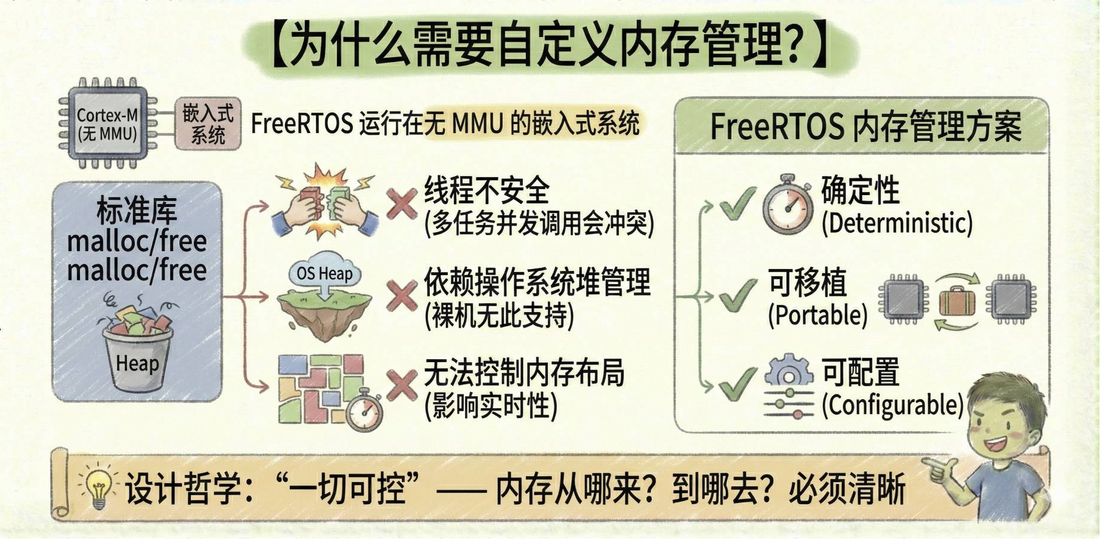

课件指出直接依赖标准库 `malloc()`、`free()` 时需要关注三个问题：

| 问题 | 对本课程工程的影响 |
|---|---|
| 多任务访问保护 | 如果标准库分配器没有适合当前RTOS的保护，任务交错操作堆管理数据可能产生冲突 |
| 实现依赖 | 分配器的行为、堆来源及初始化方式取决于编译器运行库与链接配置 |
| 布局和实时性 | 必须知道分配来自哪段RAM、如何回收，以及分配耗时和碎片风险 |

FreeRTOS把动态内存接口与具体管理实现分开，让工程选择适合自己的策略。原课用“一切可控”强调：内存从哪里来、分配给谁、如何归还，应有清楚的安排。

> 原课表述核对：无MMU并不表示裸机不能使用 `malloc()`。嵌入式C运行库可以在链接器提供的堆区域中工作，也不一定依赖另一套操作系统。标准库是否线程安全、怎样配置堆，需要查看所用工具链，不能一概而论。

课件把“确定性、可移植、可配置”作为目标，第11页又强调线程安全。这里的确定性是对资源与执行行为的控制需求，不代表五种策略都有相同或固定的执行时间：遍历空闲链表的耗时仍与当前堆状态有关，`heap_3` 则依赖标准库实现。


## 3. 五种策略的位置与统一接口

第5页给出策略文件所在目录：

```text
FreeRTOS/portable/MemMang/
├── heap_1.c
├── heap_2.c
├── heap_3.c
├── heap_4.c
└── heap_5.c
```

课程前面导入工程时的源码布局带有 `Source` 层，因此对应文件在 `FreeRTOS/Source/portable/MemMang/`。两种写法都指所用内核源码中的 `portable/MemMang` 目录。

各策略提供相同的核心接口。以下声明依据参考内核补充，用来理解“上层调用不变，底层策略不同”：

```c
void *pvPortMalloc(size_t xWantedSize);
void vPortFree(void *pv);
```

`pvPortMalloc()` 的大小参数按字节计算，成功时返回分配地址，失败时返回 `NULL`。这与 `xTaskCreate()` 的任务栈深度按栈元素计算不同。

| 策略 | 内存来源 | 可否释放 | 主要区别 |
|---|---|---|---|
| `heap_1` | 一个预留数组 `ucHeap[]` | 不支持有效回收 | 顺序分配，适合只创建、不删除的系统 |
| `heap_2` | 一个预留数组 `ucHeap[]` | 支持 | 不合并相邻空闲块；参考实现按块大小寻找最合适的块 |
| `heap_3` | C运行库的堆 | 支持 | 包装标准库 `malloc()`、`free()` |
| `heap_4` | 一个预留数组 `ucHeap[]` | 支持 | 首次适配，合并相邻空闲块，课程推荐 |
| `heap_5` | 应用描述的多个内存区域 | 支持 | 在多个区域上进行类似 `heap_4` 的管理 |

> 原课表述核对：第5、6页把 `heap_2` 写成“首次适配”。参考实现的空闲链表按块大小从小到大排列，选择能满足请求的最小合适块，通常称为**最佳适配（best fit）**；`heap_4` 才是按地址顺序查找的首次适配（first fit）。这一区别不改变原课关于 `heap_2` 不合并碎片的结论。

PPT在文件名旁标有6KB、16KB、3KB、21KB、23KB，但没有说明统计口径。不能把这些标注当作运行时堆容量，也不能据此判断应用最多能申请多少内存。

在第02、03篇的现有工程中已经加入 `heap_4.c`。**同一个工程只编译一种 `heap_x.c`**，它们提供同名接口；切换策略时替换参与编译的文件，不能把五份一起加入。


## 4. heap_1：只申请，不释放

第6页先比较 `heap_1` 与 `heap_2`。`heap_1` 的核心是预先准备一个大数组 `ucHeap[]`，然后从中按顺序分配。

参考实现使用 `xNextFreeByte` 记录下一段可分配位置：每次申请先处理对齐，再检查剩余空间；成功后返回当前位置，并把这个位置向后推进。

```text
初始：下一分配位置在数组起始处
申请A：划出A需要的空间，位置向后移动
申请B：继续划出B的空间，位置再次向后移动
释放A：该策略不会将A归还为可重新使用的空间
```

原课强调它“只增不减”，适用于启动时一次创建固定任务、之后永不删除的场景。实现简单，不会因反复释放形成分散空闲块，但已分配空间也不能再次使用。

| 适合条件 | 需要满足的前提 |
|---|---|
| 简单教学Demo | 只在初始化时申请，运行中无释放需求 |
| 任务和对象数量固定 | 所有长期使用的对象在启动时建立 |
| 分配需求可提前估算 | 堆容量足够，且运行中不会不断申请新对象 |

> 这里的“静态系统”指对象集合和生命周期固定，不等于第04篇的 `xTaskCreateStatic()`。用 `heap_1` 调用 `xTaskCreate()` 仍属于动态分配，只是分配后不回收。参考版本的 `vPortFree()` 不释放有效内存，并会对非空指针进行断言检查，因此不能用它支持动态对象反复创建、删除。


## 5. heap_2：能够释放，但不合并相邻空闲块

`heap_2` 在单一数组上维护空闲块链表，支持分配与释放。与 `heap_1` 相比，归还的块可以重新使用；问题是它不把相邻空闲块合并成更大的块。

下面保留第6页的比较部分。图中策略概览已在前节整理，因此这里只裁取右侧比较；`heap_2` 的分配算法以第3节核对为准。

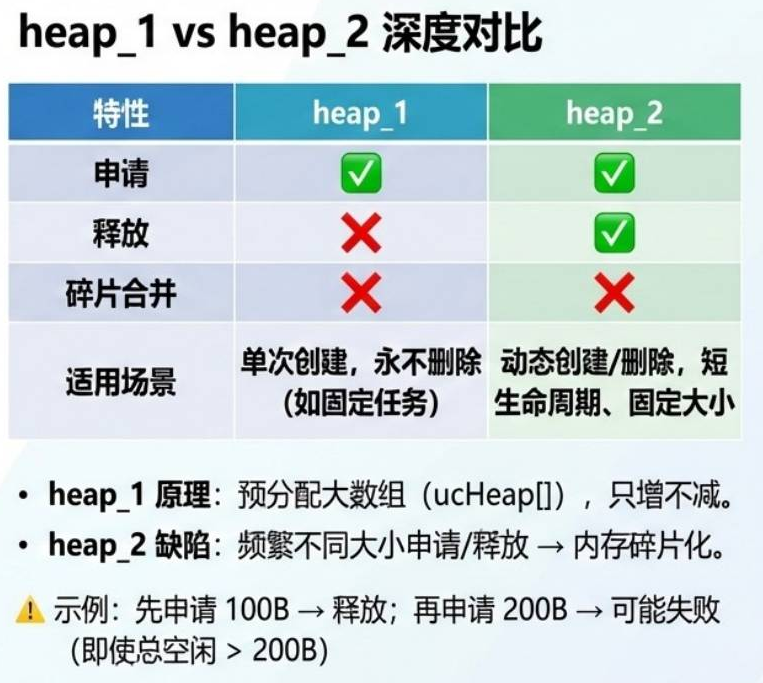

原课示例是：先申请100B，再释放，然后申请200B，即使总空闲大于200B，也可能失败。

这里的“可能”需要满足碎片条件：当前没有一个足够大的连续空闲块。仅仅做一次“申请100B再释放”，并不能单独证明接下来的200B申请一定失败；如果还有足够大的空闲块，仍可成功。

**内存碎片**在本节指空闲空间被分成多个小块，导致总量看似足够，却没有一个块能满足请求。分配还需要考虑管理头和对齐，不能只按应用请求的字节数相加。

课件将 `heap_2` 的适用场景限制为短生命周期、固定大小对象的创建和删除。它的关键弱点是频繁申请、释放不同大小的块时，碎片更容易积累。

就地核对参考实现：释放时把块重新插入按大小排序的空闲链表，但不会与前后物理相邻的空闲块合并。这正是它与后面 `heap_4` 的主要区别。


## 6. heap_3：包装标准库malloc与free

第7页把 `heap_3` 定位为“标准库代理”，课程不推荐把它作为新工程的首选，只作为已有大量 `malloc()` 代码迁移时的参考。

它把FreeRTOS接口转交给标准库，并在调用前挂起调度器，调用后恢复。PPT中的简化代码如下，只整理了缩进：

```c
void *pvPortMalloc(size_t xWantedSize)
{
    vTaskSuspendAll(); // 挂起调度器
    void *p = malloc(xWantedSize);
    xTaskResumeAll();
    return p;
}
```

这是原课用于说明包装思路的片段，不是完整 `heap_3.c`。参考文件还包含跟踪与分配失败钩子等处理；`vPortFree()` 同样在标准库 `free()` 外使用挂起、恢复调度器。

| 原课指出的风险 | 含义 |
|---|---|
| 依赖编译器标准库 | 分配算法、碎片行为及堆配置随运行库变化 |
| `malloc()` 本身可能非线程安全 | 包装器需要防止多个任务交错操作同一分配器 |
| 挂起调度器的开销 | 标准库分配期间其他任务不能被调度，执行耗时会影响任务响应 |

与第07篇衔接：`vTaskSuspendAll()` 挂起调度器，**不关闭中断**。因此这里保护的是通过同一约定使用分配器的任务访问，不能把它当作ISR安全分配接口，也不能在ISR里调用这些堆接口。

如果其他代码仍直接调用一个没有保护的标准库 `malloc()` 或 `free()`，仅给FreeRTOS包装器加保护不自动覆盖那些调用路径。是否可以统一使用，需要核对运行库与整个工程的分配方式。

`heap_3` 使用C运行库堆，需要由工具链、链接器配置相应空间；它不通过 `configTOTAL_HEAP_SIZE` 创建FreeRTOS专用数组。原课“不推荐”是课程选型意见，并非说标准库代理在任何工程中都无效。


## 7. heap_4：课程推荐，合并相邻空闲块

第8页重点讲 `heap_4`：它支持分配和释放，使用单一大数组 `ucHeap[]`，并自动合并相邻空闲块。适用于对象大小不固定、需要动态创建和删除任务、队列或信号量的系统。

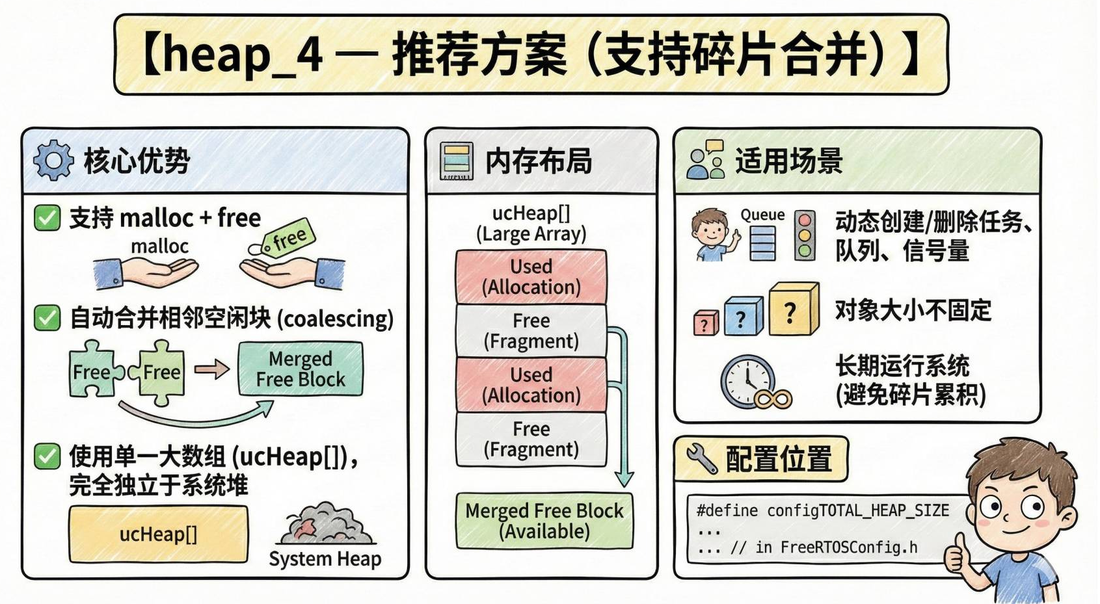

参考实现的主要过程为：

1. 空闲链表按地址排列；分配时找到第一个能容纳请求的块，即首次适配。
2. 如果找到的块比请求大，并且剩余空间能形成有效空闲块，就拆分并保留剩余部分。
3. 释放时按地址重新插入空闲链表，检查与前后空闲块是否物理相邻；相邻时合并。

**合并（coalescing）只发生在相邻空闲块之间。**图中箭头是概括性示意：如果两段空闲内存中间仍夹着已使用的块，不能把它们直接拼成一段连续空间。`heap_4` 不搬移仍在使用的对象，也不是把整个堆重新压紧。

因此，合并可以减少碎片积累，但不保证彻底消除碎片。即使总空闲量够，仍可能因为最大连续空闲块不足而分配失败；长期运行也需要检查实际分配、释放过程。

### 配置位置与堆容量

PPT给出的配置位置是 `FreeRTOSConfig.h` 中的 `configTOTAL_HEAP_SIZE`，没有在本页指定数值。沿用第02篇课程工程，它位于 `Middleware/FreeRTOS/Config/FreeRTOSConfig.h`，前文示例为：

```c
// 前面课程的配置示例，本页PPT未重新指定容量
#define configTOTAL_HEAP_SIZE ((size_t)(40 * 1024))
```

40 × 1024 = 40960字节，即40 KiB。这个容量用于 `heap_4` 的数组，不等于芯片全部RAM，也不等于任何一次申请都能获得40 KiB：还要扣除管理数据和对齐等开销。

设置容量时要留出全局数据、其他静态缓冲区及工程所需空间，不能脱离目标芯片和链接布局直接照搬数值。动态任务的栈和TCB从该堆分配；第04篇应用自行提供的静态任务栈与控制块不从这里申请。

> 图中“支持malloc＋free”是分配、释放能力的概括。`heap_4.c` 提供的是 `pvPortMalloc()`、`vPortFree()`，不会自动把标准库 `malloc()`、`free()` 重定向到 `ucHeap[]`。两种内存来源应分别核对，不能随意交叉释放。


## 8. heap_5：在多个RAM区域上管理堆

第9页介绍高级方案 `heap_5`：内存可以来自多个不连续区域，例如不同片内SRAM或外部RAM。它采用类似 `heap_4` 的分配、释放和相邻空闲块合并方式，但内存区域由应用明确描述。

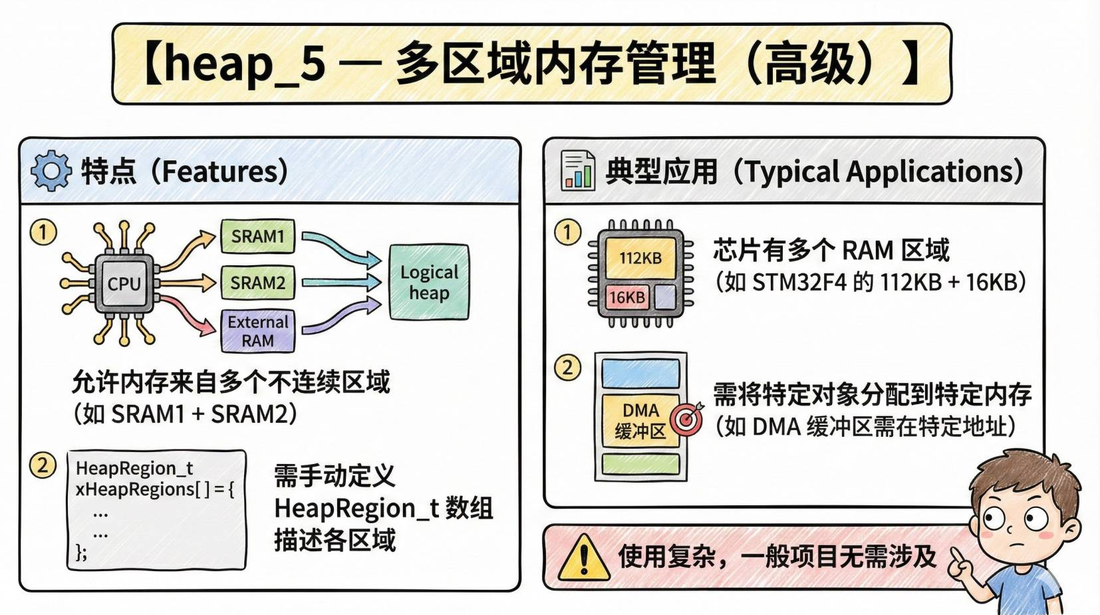

课件列出的典型场景包括：

- 芯片有多个RAM区域。PPT以STM32F4的112KB＋16KB作为示例，实际容量、地址和访问能力应按具体型号确认。
- 对内存位置有特殊要求，例如DMA缓冲区必须位于DMA能够访问的区域。

### HeapRegion_t描述什么

PPT要求手工定义 `HeapRegion_t` 数组描述各区域。以下根据参考内核补充结构成员，说明它记录的是区域起始地址与字节长度：

```c
typedef struct HeapRegion
{
    uint8_t *pucStartAddress;
    size_t xSizeInBytes;
} HeapRegion_t;
```

要在实际工程使用 `heap_5`，顺序和约束为：

1. 确认每个RAM区域已可用、长度正确，且已预留给堆；不能与全局变量、任务栈或其他缓冲区重叠。外部RAM还需要先完成硬件初始化。
2. 让 `HeapRegion_t` 数组中的区域按起始地址从低到高排列，并以 `{ NULL, 0 }` 结束。
3. 在首次动态分配之前调用 `vPortDefineHeapRegions(xHeapRegions)`，再创建使用动态内存的任务和其他内核对象。参考实现要求该定义函数只调用一次。

这些初始化条件依据参考内核补充；PPT没有展示可直接用于当前开发板的完整地址数组，因此这里不编造STM32地址。

`heap_5` 的容量来自区域描述，不是像 `heap_4` 一样仅靠 `configTOTAL_HEAP_SIZE` 定义一个数组。总可用空间还受到每段的管理数据和对齐开销影响；多个区域的总量足够，也不代表一次申请能跨越地址空洞拼成连续块。

### 多区域不等于指定对象的分配区域

> 原课表述核对：PPT将DMA缓冲区的特定地址需求列为应用场景，但标准 `pvPortMalloc()` 只接收大小参数，没有“选择区域”参数。把多个RAM区域交给 `heap_5` 后，不能保证某次申请一定落在指定区域或满足DMA访问要求；这类对象的位置仍须由工程明确安排。

本篇保留多区域管理的思路，不展开另一套专用分配器。一般单区域工程无需为了“更强”而额外使用 `heap_5`，原课也强调它的配置复杂度更高。


## 9. 工程选型：先看生命周期，再看硬件区域

第10页给出四类工程建议，并把 `heap_4` 作为课程的默认推荐。

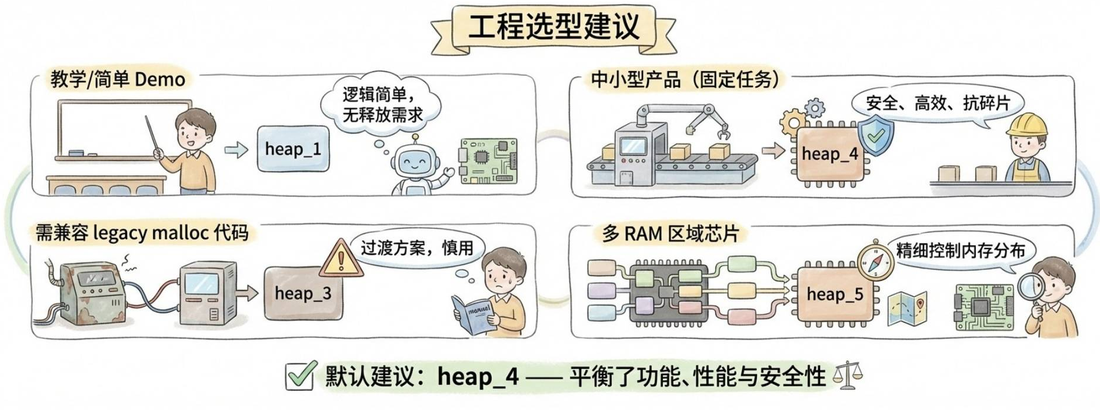

| 场景 | 原课推荐 | 判断依据 |
|---|---|---|
| 教学或简单Demo | `heap_1` | 逻辑简单，启动后没有释放需求 |
| 中小型产品，包括固定任务系统 | `heap_4` | 支持释放与相邻块合并，功能、性能与管理能力较均衡 |
| 兼容已有大量标准库分配代码 | `heap_3`，谨慎使用 | 作为迁移参考，同时确认运行库堆与访问保护 |
| 多RAM区域芯片 | `heap_5` | 明确描述可用区域，统一管理多个区域的空闲块 |

`heap_2` 在前面的对比中用于说明“支持释放”和“支持碎片合并”并不是同一件事；对频繁申请、释放不同大小对象的工程，不应只因为它能释放就忽略碎片风险。

选择时，先确认是否要释放对象、对象大小是否变化，再确认是否需要多个独立RAM区域。固定任务并不强制使用 `heap_1`：若希望保留其他对象的动态生命周期，仍可按课程使用 `heap_4`。

当前系列工程已经在第02、03篇选择 `heap_4.c`，与本课推荐一致；学习五种方案不意味着需要立即替换工程文件。


## 10. 本课要点与工程核对

原课第11页总结了五种策略：`heap_1` 只申请、`heap_2` 能释放但不合并、`heap_3` 包装标准库、`heap_4` 合并相邻空闲块、`heap_5` 管理多个区域。结合前面的实现核对，重点是区分三个问题：内存来自哪里、能否回收、回收后能否形成满足新请求的连续空间。

| 核对位置 | 应确认的内容 |
|---|---|
| 工程参与编译的源码 | 动态分配工程只包含一种 `heap_x.c`；本系列继续使用 `heap_4.c` |
| `FreeRTOSConfig.h` | 动态分配已启用；`heap_1/2/4` 的 `configTOTAL_HEAP_SIZE` 与实际RAM布局匹配 |
| 创建或申请处 | 检查动态创建返回值和 `pvPortMalloc()` 的 `NULL`，不在申请失败后继续使用无效对象 |
| 删除或释放处 | 策略支持回收；明确内存归属，使用与分配方式相配的释放接口 |
| 使用 `heap_3` 时 | 标准库堆已由工具链提供，分配器访问路径采用一致的保护方式 |
| 使用 `heap_5` 时 | 区域不重叠、按地址递增、结束项正确，初始化早于首次动态分配 |

以下是依据PPT和参考实现整理的检查方法，未进行开发板编译、下载或运行，未伪造分配结果：

1. 对照任务和对象的实际生命周期选择方案，确认不会用“只申请不释放”的 `heap_1` 承担反复创建、删除需求。
2. 在源码与配置中确认堆的真实来源和容量。不能用PPT文件名旁的KB标注代替RAM预算。
3. 比较分配、释放前后的空闲情况时，同时考虑管理头、对齐和连续块大小；总空闲量足够不能单独证明下次申请一定成功。
4. 如果观察动态任务自删后的回收，结合第06篇给Idle任务运行机会；任务自删后的部分资源回收由Idle任务稍后完成，不能紧接删除就认定回收失效。
5. 对多区域和DMA需求，进一步检查返回地址的区域及硬件访问能力，不把 `heap_5` 当作按对象指定区域的接口。

本篇完成课程中的内存管理与选型内容，后续笔记继续按既定顺序学习中断管理。
